# Phase 3 — Multi-Capability Forgetting Evaluation

**Project:** Forgetting-Aware Parameter-Efficient Fine-Tuning  
**Base model:** `Qwen/Qwen2.5-0.5B`  
**Fine-tuning target:** SAMSum  
**PEFT methods:** LoRA, AdaLoRA, DoRA

## Research question
After the same SAMSum adaptation used in Phases 1–2, do different PEFT methods preserve different pretrained capabilities?

## Important design rule
**Phase 3 does not train anything.** It loads the already-trained adapters from Phases 1–2 and evaluates additional forgetting probes. Every completed model/probe evaluation is immediately cached to Google Drive, so completed work is skipped after a Colab disconnect.

Existing probes retained from Phases 1–2:
- BoolQ — reading comprehension
- PIQA — physical commonsense

New Phase 3 probes:
- ARC-Easy — scientific/general reasoning
- MMLU (balanced subset across subjects) — broad academic/factual knowledge
- WikiText-2 — general language-modeling quality via perplexity

For accuracy probes:
`forgetting gap = PRE accuracy - POST accuracy` (positive = forgetting).

For perplexity:
`forgetting gap = POST perplexity - PRE perplexity` (positive = degradation).

**No significance claims are made in this single-seed phase.**

In [1]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
# Install dependencies.
!pip -q install -U "transformers>=4.45" "peft>=0.13" "datasets>=3.0" accelerate pandas matplotlib

In [3]:
# Mount Google Drive so Phase 2 adapters/results and Phase 3 outputs persist.
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import gc, json, math, random, re, sys, time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

def stage(name):
    print("\n" + "="*80)
    print(name)
    print("="*80)

def cleanup(*objs):
    for obj in objs:
        try:
            del obj
        except Exception:
            pass
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15
PyTorch: 2.11.0+cu128
CUDA: True
GPU: Tesla T4


## Configuration

The new probes use deterministic fixed subsets. Their indices are saved to Google Drive and reused on every rerun.

The Phase 3 evaluation budget is intentionally moderate for a Colab T4:
- ARC-Easy: 500 validation examples
- MMLU: 500 validation examples, balanced across available subjects
- WikiText-2: first 50,000 tokenizer tokens from the test split
- Scoring max length: 512 tokens

No training hyperparameter is changed because there is no training in this phase.

In [5]:
@dataclass
class Config:
    seed: int = 42
    base_model_id: str = "Qwen/Qwen2.5-0.5B"

    arc_samples: int = 500
    mmlu_samples: int = 500
    probe_max_length: int = 512
    wikitext_tokens: int = 50_000
    wikitext_block_size: int = 512

    # Phase 1 restored outputs (upload/extract outputs.zip into /content first)
    phase1_root: str = "/content/outputs"

    # Phase 2 resume-safe notebook persistence
    phase2_root: str = "/content/drive/MyDrive/forgetting-aware-peft/phase2_resume"

    # Phase 3 persistence
    phase3_root: str = "/content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability"

config = Config()

PHASE1_ROOT = Path(config.phase1_root)
PHASE2_ROOT = Path(config.phase2_root)
PHASE3_ROOT = Path(config.phase3_root)
INDEX_DIR = PHASE3_ROOT / "indices"
RESULT_DIR = PHASE3_ROOT / "results"
PLOT_DIR = PHASE3_ROOT / "plots"

for p in [INDEX_DIR, RESULT_DIR, PLOT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

random.seed(config.seed)
np.random.seed(config.seed)
torch.manual_seed(config.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Phase 3 persistent root:", PHASE3_ROOT)

Device: cuda
Phase 3 persistent root: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability


## Restore Phase 1 outputs

If `/content/outputs` is already present, this cell does nothing. Otherwise upload `outputs.zip` to the Colab Files panel and run this cell.

In [6]:
if not PHASE1_ROOT.exists():
    zip_path = Path("/content/outputs.zip")
    if not zip_path.exists():
        raise FileNotFoundError(
            "Upload outputs.zip to /content first. It must contain the Phase 1 Proper outputs."
        )
    !unzip -oq /content/outputs.zip -d /content/

assert PHASE1_ROOT.exists(), f"Missing {PHASE1_ROOT}"
print("Phase 1 outputs found:", PHASE1_ROOT)

Phase 1 outputs found: /content/outputs


## Locate the exact trained adapters

LoRA comes from Phase 1 Proper. AdaLoRA and DoRA come from the persistent Phase 2 folder.

The notebook selects the **latest completed adapter directory** matching each method. It refuses to continue if any adapter is missing.

In [7]:
def latest_matching_dir(root: Path, pattern: str):
    matches = [p for p in root.glob(pattern) if p.is_dir() and (p / "adapter_config.json").exists()]
    return sorted(matches, key=lambda p: p.stat().st_mtime)[-1] if matches else None

lora_adapter = latest_matching_dir(PHASE1_ROOT / "adapters", "*_lora_phase1_proper")
adalora_adapter = latest_matching_dir(PHASE2_ROOT / "adapters", "*_adalora_phase2_proper")
dora_adapter = latest_matching_dir(PHASE2_ROOT / "adapters", "*_dora_phase2_proper")

adapter_paths = {
    "lora": lora_adapter,
    "adalora": adalora_adapter,
    "dora": dora_adapter,
}

for method, path in adapter_paths.items():
    print(f"{method:8s} -> {path}")
    if path is None:
        raise FileNotFoundError(
            f"No completed {method} adapter found. Finish the corresponding earlier phase before Phase 3."
        )

lora     -> /content/outputs/adapters/20260816_131240_lora_phase1_proper
adalora  -> /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/adapters/20260910_070202_adalora_phase2_proper
dora     -> /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/adapters/20260910_082753_dora_phase2_proper


## Load tokenizer and new evaluation datasets

Dataset roles remain strictly separated: ARC-Easy, MMLU and WikiText-2 are **evaluation-only** and are never used for training.

In [8]:
stage("Loading tokenizer and Phase 3 datasets")

tokenizer = AutoTokenizer.from_pretrained(config.base_model_id, use_fast=True)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

arc_ds = load_dataset("allenai/ai2_arc", "ARC-Easy")
mmlu_ds = load_dataset("cais/mmlu", "all")
wikitext_ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

print("ARC splits:", arc_ds)
print("MMLU splits:", mmlu_ds)
print("WikiText splits:", wikitext_ds)


Loading tokenizer and Phase 3 datasets


ARC splits: DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'choices', 'answerKey'],
        num_rows: 2251
    })
    test: Dataset({
        features: ['id', 'question', 'choices', 'answerKey'],
        num_rows: 2376
    })
    validation: Dataset({
        features: ['id', 'question', 'choices', 'answerKey'],
        num_rows: 570
    })
})
MMLU splits: DatasetDict({
    test: Dataset({
        features: ['question', 'subject', 'choices', 'answer'],
        num_rows: 14042
    })
    validation: Dataset({
        features: ['question', 'subject', 'choices', 'answer'],
        num_rows: 1531
    })
    dev: Dataset({
        features: ['question', 'subject', 'choices', 'answer'],
        num_rows: 285
    })
    auxiliary_train: Dataset({
        features: ['question', 'subject', 'choices', 'answer'],
        num_rows: 99842
    })
})
WikiText splits: DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Datase

## Fixed Phase 3 subsets

ARC uses a fixed random sample from validation.

MMLU uses a deterministic balanced sample across the `subject` values in the validation split. We save the exact selected row indices, so PRE and every POST model see identical examples.

In [9]:
def fixed_random_indices(n_total, n_select, seed, path):
    if path.exists():
        return json.loads(path.read_text())
    rng = random.Random(seed)
    n_select = min(n_select, n_total)
    idx = sorted(rng.sample(range(n_total), n_select))
    path.write_text(json.dumps(idx, indent=2))
    return idx

arc_split = arc_ds["validation"]
arc_idx = fixed_random_indices(
    len(arc_split), config.arc_samples, config.seed, INDEX_DIR / "arc_easy_indices.json"
)
arc_examples = arc_split.select(arc_idx)

mmlu_split = mmlu_ds["validation"]
mmlu_index_path = INDEX_DIR / "mmlu_balanced_indices.json"

if mmlu_index_path.exists():
    mmlu_idx = json.loads(mmlu_index_path.read_text())
else:
    subject_to_indices = {}
    for i, subject in enumerate(mmlu_split["subject"]):
        subject_to_indices.setdefault(subject, []).append(i)

    rng = random.Random(config.seed)
    subjects = sorted(subject_to_indices)
    for s in subjects:
        rng.shuffle(subject_to_indices[s])

    chosen = []
    cursor = {s: 0 for s in subjects}
    while len(chosen) < min(config.mmlu_samples, len(mmlu_split)):
        added = False
        for s in subjects:
            j = cursor[s]
            if j < len(subject_to_indices[s]) and len(chosen) < config.mmlu_samples:
                chosen.append(subject_to_indices[s][j])
                cursor[s] += 1
                added = True
        if not added:
            break
    mmlu_idx = sorted(chosen)
    mmlu_index_path.write_text(json.dumps(mmlu_idx, indent=2))

mmlu_examples = mmlu_split.select(mmlu_idx)

print("ARC-Easy examples:", len(arc_examples))
print("MMLU examples:", len(mmlu_examples))
print("MMLU subjects represented:", len(set(mmlu_examples["subject"])))

ARC-Easy examples: 500
MMLU examples: 500
MMLU subjects represented: 57


## Shared continuation log-likelihood scorer

ARC-Easy and MMLU are scored by comparing the candidate answer continuations under the causal LM.

As in the existing PIQA methodology, each candidate score is the **mean continuation token log-likelihood** (sum of continuation-token log-probabilities divided by continuation length). Prompt tokens do not contribute to the candidate score.

The same exact implementation is used for the base model and all three PEFT models.

In [10]:
@torch.inference_mode()
def continuation_log_likelihood(model, tokenizer, prompt, continuation, device, max_length=512):
    prompt_ids = tokenizer(prompt, add_special_tokens=False).input_ids
    cont_ids = tokenizer(continuation, add_special_tokens=False).input_ids

    # Preserve the entire continuation; truncate only from the LEFT of the prompt if needed.
    max_prompt = max_length - len(cont_ids)
    if max_prompt <= 0:
        raise ValueError("Continuation itself exceeds max_length.")
    prompt_ids = prompt_ids[-max_prompt:]

    input_ids = torch.tensor([prompt_ids + cont_ids], dtype=torch.long, device=device)
    logits = model(input_ids=input_ids).logits

    # logits at position t predict token t+1
    start = len(prompt_ids) - 1
    end = start + len(cont_ids)
    pred_logits = logits[:, start:end, :]
    targets = torch.tensor([cont_ids], dtype=torch.long, device=device)

    log_probs = F.log_softmax(pred_logits, dim=-1)
    token_lp = log_probs.gather(-1, targets.unsqueeze(-1)).squeeze(-1)
    return token_lp.sum().item(), len(cont_ids)

def mean_continuation_score(model, tokenizer, prompt, continuation, device, max_length):
    total_lp, n = continuation_log_likelihood(
        model, tokenizer, prompt, continuation, device, max_length
    )
    return total_lp / n

## ARC-Easy evaluation

The prompt contains the question and labeled answer choices. Each label (`A`, `B`, …) is scored as the continuation after `Answer:`.

In [11]:
def arc_choice_data(ex):
    labels = list(ex["choices"]["label"])
    texts = list(ex["choices"]["text"])
    answer = str(ex["answerKey"])

    # Some ARC rows can use numeric labels. Normalize to the actual listed label.
    if answer not in labels and answer.isdigit():
        pos = int(answer) - 1
        if 0 <= pos < len(labels):
            answer = labels[pos]
    return labels, texts, answer

@torch.inference_mode()
def evaluate_arc(model, tokenizer, examples, device, max_length):
    model.eval()
    correct = 0
    for ex in examples:
        labels, texts, gold = arc_choice_data(ex)
        choices_text = "\n".join(f"{lab}. {txt}" for lab, txt in zip(labels, texts))
        prompt = f"Question: {ex['question']}\nChoices:\n{choices_text}\nAnswer:"
        scores = [
            mean_continuation_score(model, tokenizer, prompt, " " + lab, device, max_length)
            for lab in labels
        ]
        pred = labels[int(np.argmax(scores))]
        correct += int(pred == gold)
    return {"accuracy": correct / len(examples), "n_examples": len(examples)}

## MMLU evaluation

This is a **zero-shot** probe: no demonstrations are added. The prompt contains the subject, question and four options. Candidate labels A/B/C/D are scored with the same continuation-likelihood method for every model state.

In [12]:
MMLU_LABELS = ["A", "B", "C", "D"]

@torch.inference_mode()
def evaluate_mmlu(model, tokenizer, examples, device, max_length):
    model.eval()
    correct = 0
    per_subject = {}

    for ex in examples:
        choices = list(ex["choices"])
        subject = ex["subject"]
        options = "\n".join(f"{MMLU_LABELS[i]}. {c}" for i, c in enumerate(choices))
        prompt = (
            f"Subject: {subject.replace('_', ' ')}\n"
            f"Question: {ex['question']}\n"
            f"Choices:\n{options}\nAnswer:"
        )
        scores = [
            mean_continuation_score(model, tokenizer, prompt, " " + lab, device, max_length)
            for lab in MMLU_LABELS[:len(choices)]
        ]
        pred = int(np.argmax(scores))
        gold = int(ex["answer"])
        ok = int(pred == gold)
        correct += ok
        stats = per_subject.setdefault(subject, [0, 0])
        stats[0] += ok
        stats[1] += 1

    subject_acc = {s: c/n for s, (c, n) in per_subject.items()}
    return {
        "accuracy": correct / len(examples),
        "n_examples": len(examples),
        "subject_accuracy": subject_acc,
    }

## WikiText-2 perplexity

The test split is concatenated and tokenized. We evaluate a fixed first-token budget, divide it into non-overlapping blocks, and compute causal next-token negative log-likelihood.

Exactly the same token IDs and block boundaries are used for PRE and POST.

Perplexity is `exp(mean NLL)`. Unlike accuracy, **higher is worse**, so its forgetting gap is defined as `POST - PRE`.

In [13]:
stage("Preparing fixed WikiText-2 token stream")

wiki_text = "\n\n".join(x for x in wikitext_ds["test"]["text"] if x.strip())
wiki_ids = tokenizer(wiki_text, add_special_tokens=False).input_ids[:config.wikitext_tokens]
wiki_ids = torch.tensor(wiki_ids, dtype=torch.long)

print("WikiText tokens:", len(wiki_ids))

@torch.inference_mode()
def evaluate_wikitext_ppl(model, token_ids, device, block_size=512):
    model.eval()
    total_nll = 0.0
    total_pred_tokens = 0

    for start in range(0, len(token_ids) - 1, block_size):
        block = token_ids[start:start + block_size]
        if len(block) < 2:
            continue
        x = block.unsqueeze(0).to(device)
        logits = model(input_ids=x).logits[:, :-1, :]
        labels = x[:, 1:]
        loss_sum = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            labels.reshape(-1),
            reduction="sum"
        )
        total_nll += loss_sum.item()
        total_pred_tokens += labels.numel()

    mean_nll = total_nll / total_pred_tokens
    return {
        "perplexity": math.exp(mean_nll),
        "mean_nll": mean_nll,
        "n_pred_tokens": total_pred_tokens,
    }


Preparing fixed WikiText-2 token stream


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (298938 > 131072). Running this sequence through the model will result in indexing errors


WikiText tokens: 50000


# Evaluation

We evaluate the **base model once** to establish PRE scores, then load one PEFT adapter at a time and evaluate POST scores. Models are explicitly released between methods to keep T4 memory usage low.

In [14]:
EVAL_CACHE_DIR = PHASE3_ROOT / "eval_cache"
EVAL_CACHE_DIR.mkdir(parents=True, exist_ok=True)

def _cache_path(label, probe):
    return EVAL_CACHE_DIR / f"{label.lower()}__{probe}.json"

def _cached(label, probe):
    p = _cache_path(label, probe)
    if p.exists():
        try:
            x=json.loads(p.read_text())
            if x.get("seed")==config.seed and x.get("base_model")==config.base_model_id:
                print("CACHE HIT:", p.name)
                return x["result"]
        except Exception:
            pass
    return None

def _save(label, probe, result):
    p=_cache_path(label, probe)
    tmp=p.with_suffix(".tmp")
    tmp.write_text(json.dumps({"seed":config.seed,"base_model":config.base_model_id,"result":result}, indent=2))
    tmp.replace(p)
    print("Saved:", p)
    return result

def load_base():
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32
    m=AutoModelForCausalLM.from_pretrained(config.base_model_id, torch_dtype=dtype, low_cpu_mem_usage=True)
    m.to(device); m.eval(); return m

def evaluate_probe(model,label,probe):
    x=_cached(label,probe)
    if x is not None: return x
    if probe=="arc_easy": x=evaluate_arc(model,tokenizer,arc_examples,device,config.probe_max_length)
    elif probe=="mmlu": x=evaluate_mmlu(model,tokenizer,mmlu_examples,device,config.probe_max_length)
    elif probe=="wikitext2": x=evaluate_wikitext_ppl(model,wiki_ids,device,config.wikitext_block_size)
    else: raise ValueError(probe)
    return _save(label,probe,x)

def collect(label, model=None):
    probes=["arc_easy","mmlu","wikitext2"]
    if all(_cached(label,p) is not None for p in probes):
        return {p:_cached(label,p) for p in probes}
    assert model is not None
    return {p:evaluate_probe(model,label,p) for p in probes}


In [15]:
stage("PRE evaluation — untouched base Qwen")
if all(_cached("base_pre",p) is not None for p in ["arc_easy","mmlu","wikitext2"]):
    pre=collect("base_pre")
else:
    base_model=load_base(); pre=collect("base_pre",base_model); del base_model
    gc.collect();
    if torch.cuda.is_available(): torch.cuda.empty_cache()



PRE evaluation — untouched base Qwen
CACHE HIT: base_pre__arc_easy.json
CACHE HIT: base_pre__mmlu.json
CACHE HIT: base_pre__wikitext2.json
CACHE HIT: base_pre__arc_easy.json
CACHE HIT: base_pre__mmlu.json
CACHE HIT: base_pre__wikitext2.json
CACHE HIT: base_pre__arc_easy.json
CACHE HIT: base_pre__mmlu.json
CACHE HIT: base_pre__wikitext2.json


In [16]:
post={}
for method in ["lora","adalora","dora"]:
    probes=["arc_easy","mmlu","wikitext2"]
    if all(_cached(method,p) is not None for p in probes):
        post[method]=collect(method); continue
    base=load_base(); model=PeftModel.from_pretrained(base,str(adapter_paths[method])); model.to(device); model.eval()
    post[method]=collect(method,model)
    del model, base; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
print("Persistent evaluation cache:", EVAL_CACHE_DIR)


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache/lora__arc_easy.json
Saved: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache/lora__mmlu.json
Saved: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache/lora__wikitext2.json


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache/adalora__arc_easy.json
Saved: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache/adalora__mmlu.json
Saved: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache/adalora__wikitext2.json


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache/dora__arc_easy.json
Saved: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache/dora__mmlu.json
Saved: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache/dora__wikitext2.json
Persistent evaluation cache: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/eval_cache


## Compute Phase 3 forgetting gaps

Positive always means degradation:
- ARC/MMLU: `PRE accuracy - POST accuracy`
- WikiText-2: `POST perplexity - PRE perplexity`

In [17]:
rows = []
for method in ["lora", "adalora", "dora"]:
    row = {
        "method": method,
        "arc_pre": pre["arc_easy"]["accuracy"],
        "arc_post": post[method]["arc_easy"]["accuracy"],
        "arc_forgetting_gap": pre["arc_easy"]["accuracy"] - post[method]["arc_easy"]["accuracy"],

        "mmlu_pre": pre["mmlu"]["accuracy"],
        "mmlu_post": post[method]["mmlu"]["accuracy"],
        "mmlu_forgetting_gap": pre["mmlu"]["accuracy"] - post[method]["mmlu"]["accuracy"],

        "wikitext_ppl_pre": pre["wikitext2"]["perplexity"],
        "wikitext_ppl_post": post[method]["wikitext2"]["perplexity"],
        "wikitext_ppl_forgetting_gap": post[method]["wikitext2"]["perplexity"] - pre["wikitext2"]["perplexity"],
    }
    rows.append(row)

phase3_df = pd.DataFrame(rows)
phase3_df

,method,arc_pre,arc_post,arc_forgetting_gap,mmlu_pre,mmlu_post,mmlu_forgetting_gap,wikitext_ppl_pre,wikitext_ppl_post,wikitext_ppl_forgetting_gap
0,lora,0.718,0.716,0.002,0.454,0.460,-0.006,17.2027,18.029844,0.827144
1,adalora,0.718,0.714,0.004,0.454,0.458,-0.004,17.2027,17.198046,-0.004653
2,dora,0.718,0.716,0.002,0.454,0.464,-0.010,17.2027,18.164024,0.961324


## Import existing BoolQ/PIQA results from Phases 1–2

These are **not recomputed** in Phase 3. We reuse the already-recorded controlled Phase 1/2 results so Phase 3 does not alter those experiments.

In [18]:
def latest_json_matching(root: Path, pattern: str):
    matches = [p for p in root.glob(pattern) if p.is_file()]
    return sorted(matches, key=lambda p: p.stat().st_mtime)[-1] if matches else None

lora_result_path = latest_json_matching(PHASE1_ROOT / "results", "*_lora_phase1_proper.json")
adalora_result_path = latest_json_matching(PHASE2_ROOT / "results", "*_adalora_phase2_proper.json")
dora_result_path = latest_json_matching(PHASE2_ROOT / "results", "*_dora_phase2_proper.json")

old_paths = {
    "lora": lora_result_path,
    "adalora": adalora_result_path,
    "dora": dora_result_path,
}

old_results = {}
for method, p in old_paths.items():
    if p is None:
        raise FileNotFoundError(f"Missing prior result JSON for {method}.")
    old_results[method] = json.loads(p.read_text())
    print(method, "->", p)

for i, row in phase3_df.iterrows():
    method = row["method"]
    phase3_df.loc[i, "boolq_forgetting_gap"] = old_results[method]["boolq_forgetting_gap"]
    phase3_df.loc[i, "piqa_forgetting_gap"] = old_results[method]["piqa_forgetting_gap"]
    phase3_df.loc[i, "samsum_rougeL_gain"] = old_results[method]["samsum_rougeL_gain"]

phase3_df

lora -> /content/outputs/results/20260816_131240_lora_phase1_proper.json
adalora -> /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/results/20260910_070202_adalora_phase2_proper.json
dora -> /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/results/20260910_082753_dora_phase2_proper.json


,method,arc_pre,arc_post,arc_forgetting_gap,mmlu_pre,mmlu_post,mmlu_forgetting_gap,wikitext_ppl_pre,wikitext_ppl_post,wikitext_ppl_forgetting_gap,boolq_forgetting_gap,piqa_forgetting_gap,samsum_rougeL_gain
0,lora,0.718,0.716,0.002,0.454,0.460,-0.006,17.2027,18.029844,0.827144,-0.008,-0.016,0.098770
1,adalora,0.718,0.714,0.004,0.454,0.458,-0.004,17.2027,17.198046,-0.004653,0.006,0.000,0.067553
2,dora,0.718,0.716,0.002,0.454,0.464,-0.010,17.2027,18.164024,0.961324,-0.010,-0.016,0.110880


## Paper-oriented comparison table

Do **not** average perplexity changes with accuracy-point changes. They are different units. The table and plots keep each capability separate.

In [19]:
paper_table = phase3_df[[
    "method",
    "samsum_rougeL_gain",
    "boolq_forgetting_gap",
    "piqa_forgetting_gap",
    "arc_forgetting_gap",
    "mmlu_forgetting_gap",
    "wikitext_ppl_forgetting_gap",
]].copy()

paper_table.columns = [
    "Method",
    "SAMSum ROUGE-L Gain",
    "BoolQ Gap",
    "PIQA Gap",
    "ARC-Easy Gap",
    "MMLU Gap",
    "WikiText-2 PPL Gap",
]
paper_table

,Method,SAMSum ROUGE-L Gain,BoolQ Gap,PIQA Gap,ARC-Easy Gap,MMLU Gap,WikiText-2 PPL Gap
0,lora,0.098770,-0.008,-0.016,0.002,-0.006,0.827144
1,adalora,0.067553,0.006,0.000,0.004,-0.004,-0.004653
2,dora,0.110880,-0.010,-0.016,0.002,-0.010,0.961324


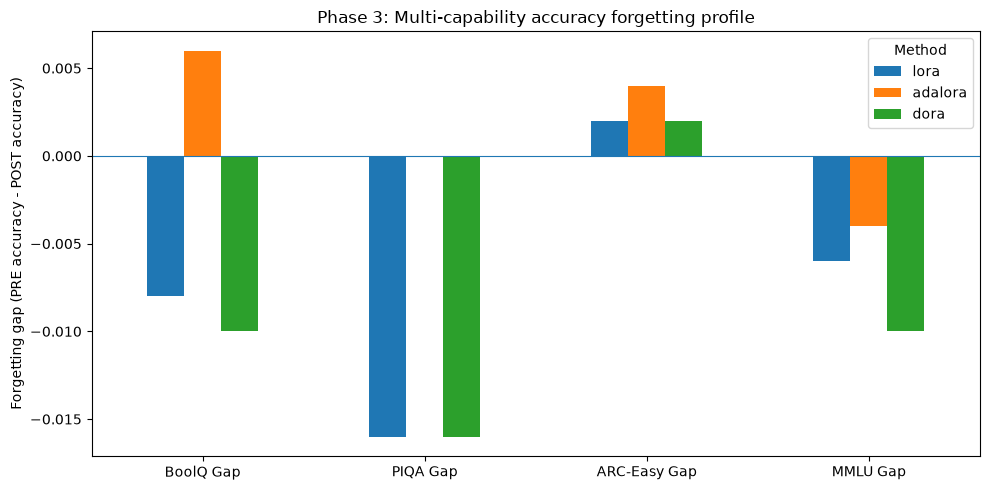

In [20]:
# Accuracy-probe forgetting profile
plot_df = paper_table.set_index("Method")[["BoolQ Gap", "PIQA Gap", "ARC-Easy Gap", "MMLU Gap"]].T

ax = plot_df.plot(kind="bar", figsize=(10, 5))
ax.axhline(0, linewidth=0.8)
ax.set_ylabel("Forgetting gap (PRE accuracy - POST accuracy)")
ax.set_title("Phase 3: Multi-capability accuracy forgetting profile")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(PLOT_DIR / "accuracy_forgetting_profile.png", dpi=200)
plt.show()

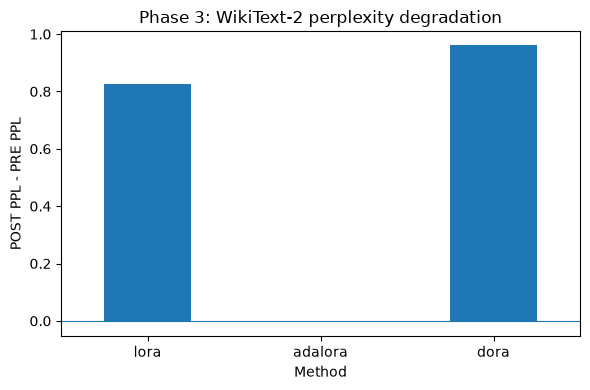

In [21]:
# WikiText perplexity degradation is plotted separately because it has different units.
ax = phase3_df.plot(
    x="method",
    y="wikitext_ppl_forgetting_gap",
    kind="bar",
    legend=False,
    figsize=(6, 4),
)
ax.axhline(0, linewidth=0.8)
ax.set_xlabel("Method")
ax.set_ylabel("POST PPL - PRE PPL")
ax.set_title("Phase 3: WikiText-2 perplexity degradation")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(PLOT_DIR / "wikitext_perplexity_gap.png", dpi=200)
plt.show()

## Save a complete, persistent Phase 3 record

The JSON contains raw PRE/POST values, per-subject MMLU accuracy, adapter paths, fixed-index locations and all forgetting gaps. The CSV is a compact paper-oriented table.

In [22]:
timestamp = time.strftime("%Y%m%d_%H%M%S")

record = {
    "experiment_id": f"{timestamp}_phase3_multicapability",
    "phase": "phase3_multicapability",
    "base_model": config.base_model_id,
    "seed": config.seed,
    "fine_tuning_target": "SAMSum",
    "methods": ["lora", "adalora", "dora"],
    "adapter_paths": {k: str(v) for k, v in adapter_paths.items()},
    "probe_design": {
        "arc_easy_samples": len(arc_examples),
        "mmlu_samples": len(mmlu_examples),
        "mmlu_subjects": len(set(mmlu_examples["subject"])),
        "wikitext_tokens": len(wiki_ids),
        "probe_max_length": config.probe_max_length,
        "accuracy_gap_definition": "PRE - POST; positive = forgetting",
        "perplexity_gap_definition": "POST - PRE; positive = degradation",
    },
    "pre": pre,
    "post": post,
    "existing_phase1_phase2": old_results,
    "summary_rows": phase3_df.to_dict(orient="records"),
    "limitations": [
        "Single seed; results are descriptive only.",
        "One fine-tuning target task (SAMSum).",
        "MMLU is evaluated zero-shot on a fixed balanced subset, not the full benchmark.",
        "WikiText-2 perplexity uses a fixed token budget and non-overlapping blocks.",
        "No statistical significance claim is made in Phase 3.",
    ],
}

json_path = RESULT_DIR / f"{record['experiment_id']}.json"
csv_path = RESULT_DIR / "phase3_multicapability_results.csv"

json_path.write_text(json.dumps(record, indent=2))
paper_table.to_csv(csv_path, index=False)

print("Saved JSON:", json_path)
print("Saved CSV :", csv_path)
print("Saved plots:", PLOT_DIR)

Saved JSON: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/results/20260913_064947_phase3_multicapability.json
Saved CSV : /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/results/phase3_multicapability_results.csv
Saved plots: /content/drive/MyDrive/forgetting-aware-peft/phase3_multicapability/plots


# Phase 3 interpretation rules

When writing the report/paper:

1. Treat each probe as a **capability-specific forgetting measurement**, not proof of global knowledge retention.
2. Positive accuracy gaps indicate forgetting; negative gaps indicate improvement.
3. Positive WikiText perplexity gap indicates worse general language modeling.
4. Do not combine accuracy gaps and perplexity gaps into a raw arithmetic average.
5. Because this phase uses one seed, describe differences as **observations**, not statistically established superiority.
6. Phase 4 should repeat the most important comparisons across multiple seeds before making stronger claims.

**Next research phase:** multi-seed robustness.